# 08 – Nelineární dynamika a teorie chaosu: Rekurenční kvantifikační analýza (RQA) a Entropie
Výpočet rekurenční matice $R_{i,j} = \Theta(\varepsilon - \|\vec{x}_i - \vec{x}_j\|)$, metrik **Recurrence Rate (`RR`)**, **Determinism (`DET`)**, **Laminarity (`LAM`)**, **Diagonal Entropy (`ENTR`)**, **Sample Entropy** a **Permutation Entropy**.

Metriky separability (RQA + Entropie): {'method_name': 'rqa_entropy', 'fdr_score': 0.4632, 'silhouette_score': -0.1173, 'davies_bouldin_score': 11.5548, 'mutual_info_mean': 0.2776, 'anova_f_mean': 487.3925, 'separability_by_phenomenon': {'static_load_fdr': 0.0563, 'thermal_fdr': 0.4604, 'transition_edge_fdr': 0.0013}}


,measurement_code,inherited_label,rqa_determinism,rqa_laminarity,sample_entropy,permutation_entropy
0,0773,klid_pred_teplotou,0.287510,0.464650,1.281891,0.917038
1,0773,klid_pred_teplotou,0.321616,0.496260,1.281501,0.940972
2,0773,klid_pred_teplotou,0.326667,0.507083,1.290446,0.921957
3,0773,klid_pred_teplotou,0.546048,0.703135,1.304252,0.922464
4,0773,klid_pred_teplotou,0.591879,0.736063,1.474402,0.896552
5,0773,klid_pred_teplotou,0.439068,0.639785,1.439349,0.920939
6,0773,klid_pred_teplotou,0.291038,0.492014,1.406439,0.945340
7,0773,klid_pred_teplotou,0.375223,0.553030,1.463853,0.954900
8,0773,klid_pred_teplotou,0.412698,0.631393,1.209278,0.938360
9,0773,klid_pred_teplotou,0.468525,0.672662,1.300581,0.882647


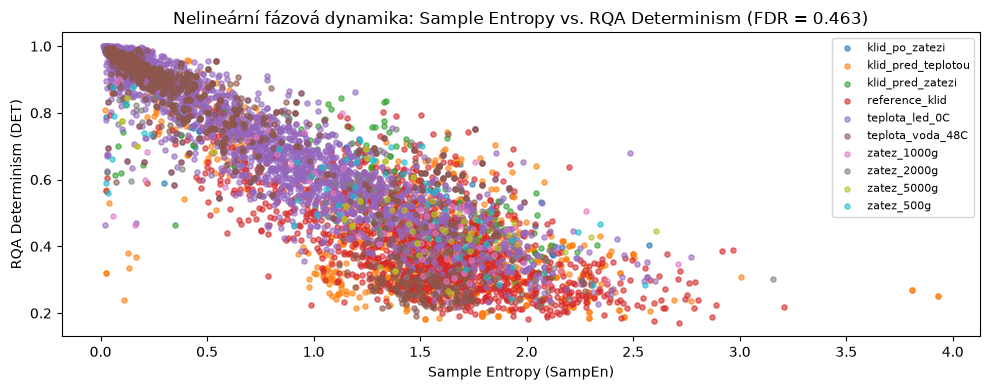

In [1]:
import matplotlib.pyplot as plt
from icaros.analysis.runner import load_windows_with_signals, run_single_silver_method
from icaros.db.s3 import read_parquet_from_s3

df_win, signals, fs = load_windows_with_signals("win128_stride32")
res = run_single_silver_method("rqa_entropy", df_win, signals, fs, "win128_stride32")
print("Metriky separability (RQA + Entropie):", {k: v for k, v in res.items() if k != "s3_uri"})
df_rqa = read_parquet_from_s3(res["s3_uri"])
display(df_rqa[["measurement_code", "inherited_label", "rqa_determinism", "rqa_laminarity", "sample_entropy", "permutation_entropy"]].head(12))

fig, ax = plt.subplots(figsize=(10, 4))
for lbl, grp in df_rqa.groupby("inherited_label"):
    ax.scatter(grp["sample_entropy"], grp["rqa_determinism"], s=14, alpha=0.6, label=lbl)
ax.set_xlabel("Sample Entropy (SampEn)")
ax.set_ylabel("RQA Determinism (DET)")
ax.set_title("Nelineární fázová dynamika: Sample Entropy vs. RQA Determinism (FDR = 0.463)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()